# 1. K-Nearest Neighbors (KNN) — Bank Marketing Classification

This notebook implements K-Nearest Neighbors (KNN) to predict whether a customer will subscribe to a term deposit.

The model uses the Bank Marketing dataset and the reusable preprocessing pipeline developed earlier.

The goal is to train, tune, and evaluate KNN using the same data splits and evaluation metrics as Logistic Regression for a fair comparison.

In [10]:
from pathlib import Path
import sys

import numpy as np
import pandas as pd
import joblib

from sklearn.model_selection import train_test_split

# Project constants
TARGET_COLUMN = "y"
RANDOM_STATE = 42

# Identify project root
CURRENT_DIR = Path.cwd()

if CURRENT_DIR.name == "notebooks":
    PROJECT_ROOT = CURRENT_DIR.parent
else:
    PROJECT_ROOT = CURRENT_DIR

# Add project root to Python path
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

# Import reusable KNN functions
from src.knn import (
    build_knn_pipeline,
    tune_knn
)

# Import shared evaluation functions
from src.evaluation import (
    evaluate_binary_classifier,
    results_to_dataframe,
    plot_confusion_matrix,
    plot_roc_curve
)

print("KNN environment ready.")

KNN environment ready.


## 2. Data Loading and Splitting

We use the Bank Marketing dataset to predict whether a customer will subscribe to a term deposit (`y`).

The target variable is converted to binary values (1 = Yes, 0 = No). We exclude selected features based on our preprocessing decisions and split the data into training (70%), validation (15%), and testing (15%) sets.

We used the same data preparation settings as Logistic Regression to ensure consistent model comparison.

In [11]:
# Load dataset
df = pd.read_csv(PROJECT_ROOT / "data" / "bank-full.csv", sep=";")

# Encode target variable
y = df[TARGET_COLUMN].map({"yes": 1, "no": 0})

# Exclude the same features used in Logistic Regression
features_to_exclude = ["default", "day", "duration", "pdays", "poutcome"]

X = df.drop(columns=[TARGET_COLUMN] + features_to_exclude)

# Identify numerical and categorical features
numerical_features = X.select_dtypes(
    include=["number"]
).columns.tolist()

categorical_features = X.select_dtypes(
    include=["object", "str", "category"]
).columns.tolist()

# Stratified 70/15/15 split
X_train, X_temp, y_train, y_temp = train_test_split(
    X, y,
    test_size=0.30,
    random_state=RANDOM_STATE,
    stratify=y
)

X_test, X_val, y_test, y_val = train_test_split(
    X_temp, y_temp,
    test_size=0.50,
    random_state=RANDOM_STATE,
    stratify=y_temp
)

# Verify dataset dimensions
print("Original dataset:", df.shape)
print("Training:", X_train.shape)
print("Validation:", X_val.shape)
print("Testing:", X_test.shape)

print("\nNumerical features:", numerical_features)
print("Categorical features:", categorical_features)

# Verify target distribution
for name, target in [
    ("Training", y_train),
    ("Validation", y_val),
    ("Testing", y_test)
]:
    print(f"{name} positive class: {target.mean() * 100:.2f}%")

Original dataset: (45211, 17)
Training: (31647, 11)
Validation: (6782, 11)
Testing: (6782, 11)

Numerical features: ['age', 'balance', 'campaign', 'previous']
Categorical features: ['job', 'marital', 'education', 'housing', 'loan', 'contact', 'month']
Training positive class: 11.70%
Validation positive class: 11.69%
Testing positive class: 11.71%


## 3. Build KNN Pipeline

We created a machine learning pipeline that combines numerical and categorical preprocessing with K-Nearest Neighbors (KNN).

The pipeline ensures that preprocessing is fitted only on the training data, preventing data leakage.

The pipeline applies feature scaling and one-hot encoding before training KNN, ensuring that distance calculations use consistently processed features.

In [12]:
# Build baseline KNN pipeline using reusable module
knn_pipeline = build_knn_pipeline(
    numerical_features,
    categorical_features
)

print("KNN pipeline created successfully.")
print(knn_pipeline)

KNN pipeline created successfully.
Pipeline(steps=[('preprocessor',
                 ColumnTransformer(transformers=[('numeric',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='median')),
                                                                  ('scaler',
                                                                   StandardScaler())]),
                                                  ['age', 'balance', 'campaign',
                                                   'previous']),
                                                 ('categorical',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='most_frequent')),
                                                                  ('onehot',
                                                   

## 4. Train Baseline KNN Model

We trained the KNN pipeline using the training dataset.

The pipeline automatically applies numerical scaling and categorical encoding before fitting the KNN classifier. The validation and test datasets are not used during training.

The baseline model uses 5 neighbors, uniform weights, and Euclidean distance.

In [13]:
# Train baseline KNN model
knn_pipeline.fit(X_train, y_train)

print("Baseline KNN model trained successfully.")

# Verify fitted model
print("\nModel classes:", knn_pipeline.classes_)
print("Number of training samples:", len(X_train))
print("Number of features:", X_train.shape[1])

Baseline KNN model trained successfully.

Model classes: [0 1]
Number of training samples: 31647
Number of features: 11


## 5. Evaluate Baseline KNN Model

We evaluated the baseline KNN classifier on the validation dataset using the shared evaluation functions from `src/evaluation.py`.

The following performance metrics are calculated:

- Accuracy
- Precision
- Recall
- F1-score
- ROC-AUC

We also visualize the confusion matrix and ROC curve to better understand the model's classification performance.

Since the Bank Marketing dataset is imbalanced, F1-score, recall, precision, and ROC-AUC are particularly important for evaluating how well the model identifies customers who subscribe to a term deposit.

Baseline KNN — Validation Results


,model,accuracy,precision,recall,f1,roc_auc
0,Baseline KNN,0.8788,0.4444,0.1463,0.2201,0.6816


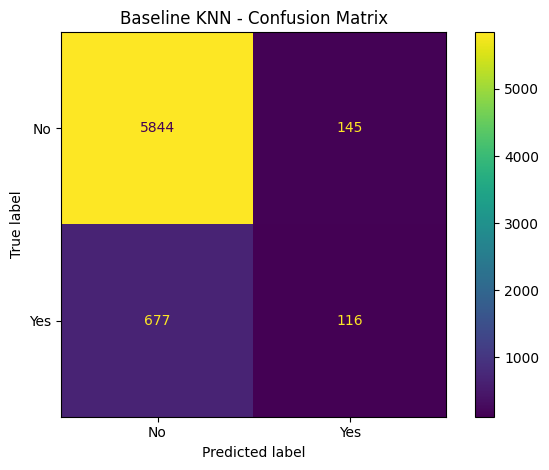

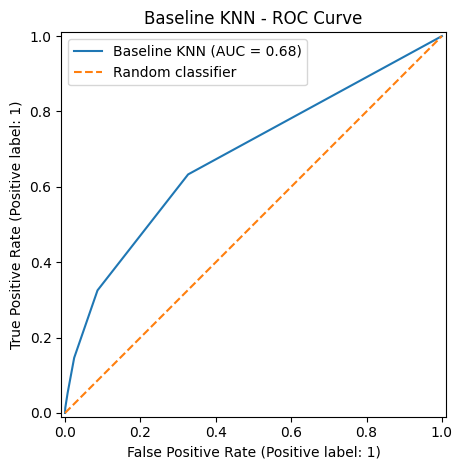

In [14]:
# Generate predictions on validation dataset
y_val_pred = knn_pipeline.predict(X_val)

# Generate probabilities for positive class
y_val_prob = knn_pipeline.predict_proba(X_val)[:, 1]

# Evaluate baseline KNN using shared evaluation function
baseline_results = evaluate_binary_classifier(
    model_name="Baseline KNN",
    y_true=y_val,
    y_pred=y_val_pred,
    y_score=y_val_prob
)

# Display evaluation metrics
print("Baseline KNN — Validation Results")
display(results_to_dataframe([baseline_results]).round(4))

# Plot confusion matrix
plot_confusion_matrix(
    y_val,
    y_val_pred,
    "Baseline KNN"
)

# Plot ROC curve
plot_roc_curve(
    y_val,
    y_val_prob,
    "Baseline KNN"
)

## 6. Hyperparameter Tuning

We used GridSearchCV with stratified 3-fold cross-validation to find the best KNN hyperparameters.

The search evaluates different numbers of neighbors (`n_neighbors`) and weighting methods (`weights`), using F1-score as the optimization metric.

F1-score is used to select the best model because the dataset contains substantially fewer subscribers than non-subscribers.

In [15]:
# Perform hyperparameter tuning
knn_grid_search = tune_knn(
    knn_pipeline,
    X_train,
    y_train,
    random_state=RANDOM_STATE
)

# Display best hyperparameters
print("\nBest KNN Parameters:")
print(knn_grid_search.best_params_)

print("\nBest Cross-Validation F1-score:")
print(f"{knn_grid_search.best_score_:.4f}")

# Store best fitted model
best_knn_model = knn_grid_search.best_estimator_

print("\nBest KNN Model:")
print(best_knn_model.named_steps["classifier"])

Fitting 3 folds for each of 8 candidates, totalling 24 fits

Best KNN Parameters:
{'classifier__n_neighbors': 5, 'classifier__weights': 'distance'}

Best Cross-Validation F1-score:
0.2310

Best KNN Model:
KNeighborsClassifier(weights='distance')


## 7. Baseline vs. Tuned KNN

We evaluate the tuned KNN model on the validation dataset and compare its performance with the baseline model.

The comparison focuses on accuracy, precision, recall, F1-score, and ROC-AUC to understand how hyperparameter tuning affects classification performance.

We use the shared evaluation functions from `src/evaluation.py` to calculate metrics and visualize the tuned model's confusion matrix and ROC curve.

Baseline vs. Tuned KNN — Validation Results


,model,accuracy,precision,recall,f1,roc_auc
0,Baseline KNN,0.8788,0.4444,0.1463,0.2201,0.6816
1,Tuned KNN,0.8711,0.3784,0.1589,0.2238,0.6830


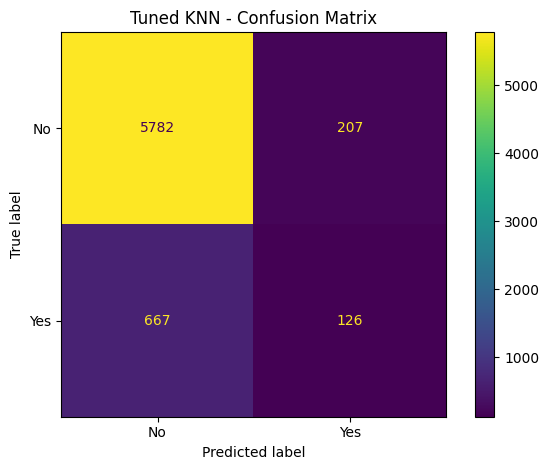

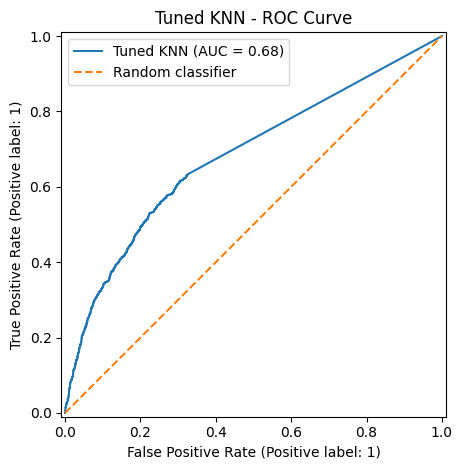

In [16]:
# Generate predictions using the tuned KNN model
y_val_pred_tuned = best_knn_model.predict(X_val)

# Generate positive-class probabilities
y_val_prob_tuned = best_knn_model.predict_proba(X_val)[:, 1]

# Evaluate tuned KNN using shared evaluation function
tuned_results = evaluate_binary_classifier(
    model_name="Tuned KNN",
    y_true=y_val,
    y_pred=y_val_pred_tuned,
    y_score=y_val_prob_tuned
)

# Compare baseline and tuned KNN performance
comparison = results_to_dataframe([
    baseline_results,
    tuned_results
])

print("Baseline vs. Tuned KNN — Validation Results")
display(comparison.round(4))

# Plot tuned KNN confusion matrix
plot_confusion_matrix(
    y_val,
    y_val_pred_tuned,
    "Tuned KNN"
)

# Plot tuned KNN ROC curve
plot_roc_curve(
    y_val,
    y_val_prob_tuned,
    "Tuned KNN"
)

### Results Interpretation

- The baseline KNN model achieved higher accuracy (0.8788) and precision (0.4444) than the tuned model.
- Hyperparameter tuning slightly improved recall from 0.1463 to 0.1589 and F1-score from 0.2201 to 0.2238.
- ROC-AUC also improved slightly from 0.6816 to 0.6830.
- The tuned model correctly identified 126 customers who subscribed but missed 667 actual subscribers.
- Overall, the tuned KNN model achieved a small improvement in F1-score, but its recall remains low, indicating difficulty identifying the minority class.

## 8. Final Test Evaluation

We evaluated the tuned KNN model on the unseen test dataset to measure its final classification performance.

The test dataset was not used during model training or hyperparameter tuning, providing an independent evaluation of the selected model.

We use the shared evaluation functions from `src/evaluation.py` to calculate accuracy, precision, recall, F1-score, and ROC-AUC.

We also visualize the confusion matrix and ROC curve to better understand the model's performance on unseen data.

Tuned KNN — Test Results


,model,accuracy,precision,recall,f1,roc_auc
0,Tuned KNN,0.8758,0.4255,0.1725,0.2455,0.6821


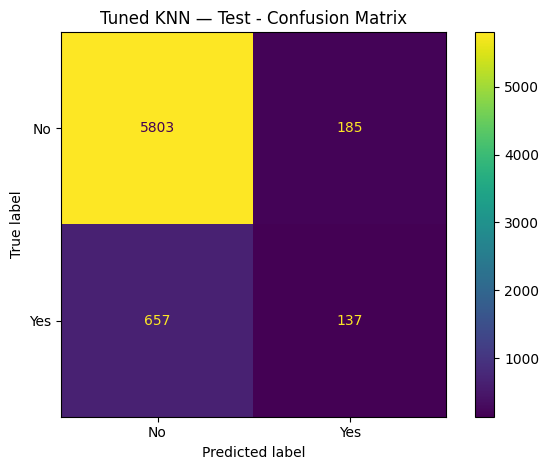

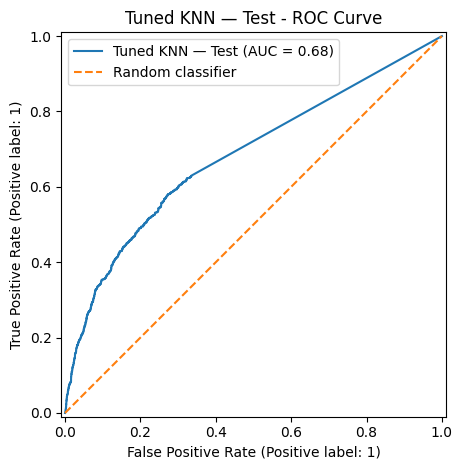

In [17]:
# Generate predictions on test dataset
y_test_pred_knn = best_knn_model.predict(X_test)

# Generate positive-class probabilities
y_test_prob_knn = best_knn_model.predict_proba(X_test)[:, 1]

# Evaluate tuned KNN on test dataset
test_results = evaluate_binary_classifier(
    model_name="Tuned KNN",
    y_true=y_test,
    y_pred=y_test_pred_knn,
    y_score=y_test_prob_knn
)

# Display final test metrics
print("Tuned KNN — Test Results")
display(results_to_dataframe([test_results]).round(4))

# Plot confusion matrix
plot_confusion_matrix(
    y_test,
    y_test_pred_knn,
    "Tuned KNN — Test"
)

# Plot ROC curve
plot_roc_curve(
    y_test,
    y_test_prob_knn,
    "Tuned KNN — Test"
)

### Results Interpretation

- The tuned KNN model achieved an accuracy of 0.8758 and precision of 0.4255 on the test dataset.
- Recall was 0.1725, indicating that the model correctly identified only 17.25% of actual subscribers.
- The F1-score was 0.2455, showing that the model still struggles to balance precision and recall.
- ROC-AUC was 0.6821, indicating moderate ability to distinguish between subscribers and non-subscribers.
- The confusion matrix shows that the model correctly identified 137 subscribers but missed 657 actual subscribers.
- Overall, the tuned KNN model performs well in terms of accuracy but has limited effectiveness in identifying the minority class.

## 9. Save and Verify Trained Model

We save the tuned KNN model using `joblib` so it can be reused without retraining.

The saved pipeline includes both preprocessing and the trained KNN classifier.

We reload the saved model and verify that it produces the same predictions as the original model.

In [18]:
# Create models directory if it does not exist
models_dir = PROJECT_ROOT / "models"
models_dir.mkdir(parents=True, exist_ok=True)

# Define model path
model_path = models_dir / "knn.joblib"

# Save the trained KNN pipeline
joblib.dump(best_knn_model, model_path)

print("KNN model saved successfully.")

# Reload saved model
loaded_knn_model = joblib.load(model_path)

print("\nKNN model loaded successfully.")

# Verify predictions match
original_predictions = best_knn_model.predict(X_test)
loaded_predictions = loaded_knn_model.predict(X_test)

print(
    "Predictions match:",
    np.array_equal(original_predictions, loaded_predictions)
)

# Verify saved model parameters
print("\nSaved KNN Parameters:")
print(loaded_knn_model.named_steps["classifier"])

KNN model saved successfully.

KNN model loaded successfully.
Predictions match: True

Saved KNN Parameters:
KNeighborsClassifier(weights='distance')
